# Soil + Groundwater Heavy-Metal Index (PLI) Prediction


In [3]:
import warnings, json, math, platform, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (KFold, LeaveOneGroupOut, RandomizedSearchCV,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
TARGET = "PLI"            # Pollution Load Index = heavy-metal index to predict
N_ITER = 6                # random-search trials per model (raise to 15-20 for a better search)
CV_FOLDS = 5

BASE_DIR = Path.cwd()
for d in ["data/raw", "data/processed", "models", "reports"]:
    (BASE_DIR / d).mkdir(parents=True, exist_ok=True)

def find_file(name):
    for folder in [BASE_DIR / "data" / "raw", BASE_DIR / "data", BASE_DIR]:
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"'{name}' not found. Put it in {BASE_DIR / 'data' / 'raw'}")

SOIL_FILE = find_file("soil_heavy_metal_pollution_5000_rows.csv")
GW_FILE = find_file("gwq_chemical_parameter_manual_cgwb_rj_1961_2025.csv")
print("sklearn", sklearn.__version__, "| python", platform.python_version())
print("soil file:", SOIL_FILE)
print("gw file  :", GW_FILE)

sklearn 1.9.1 | python 3.13.4
soil file: C:\Users\HP\soil_water_HMP\nb_project\data\raw\soil_heavy_metal_pollution_5000_rows.csv
gw file  : C:\Users\HP\soil_water_HMP\nb_project\data\raw\gwq_chemical_parameter_manual_cgwb_rj_1961_2025.csv


---
# Task 1 – Dataset Finalisation & Preprocessing  (10/08/2026 – 22/08/2026)



In [4]:
%%writefile gw_utils.py
"""Helpers shared by the notebook and the backend API."""
import numpy as np
import pandas as pd

GW_MAX_DISTANCE_KM = 50.0   # search radius soil point <-> groundwater station
GW_K_NEAREST = 5            # neighbours used in inverse-distance weighting

# column-name prefix in raw CGWB file -> short feature name
GW_COLUMN_PREFIXES = {
    "Potential of Hydrogen": "gw_pH",
    "Electric Conductivity": "gw_EC",
    "Carbonate": "gw_CO3",
    "Bicarbonate": "gw_HCO3",
    "Total Alkalinity": "gw_Alkalinity",
    "Chloride": "gw_Cl",
    "Sulphate": "gw_SO4",
    "Total Hardness": "gw_Hardness",
    "Calcium": "gw_Ca",
    "Magnesium": "gw_Mg",
    "Sodium": "gw_Na",
    "Iron": "gw_Fe",
}
GW_FEATURES = list(GW_COLUMN_PREFIXES.values())

# physically plausible limits; values outside are unit / entry errors -> NaN
GW_LIMITS = {
    "gw_pH": (5.0, 10.0), "gw_EC": (50.0, 40000.0), "gw_CO3": (0.0, 500.0),
    "gw_HCO3": (0.0, 3000.0), "gw_Alkalinity": (0.0, 3000.0), "gw_Cl": (0.0, 15000.0),
    "gw_SO4": (0.0, 10000.0), "gw_Hardness": (10.0, 10000.0), "gw_Ca": (0.0, 2000.0),
    "gw_Mg": (0.0, 1500.0), "gw_Na": (0.0, 10000.0), "gw_Fe": (0.0, 50.0),
}


def read_csv_safe(path):
    """Read a CSV with UTF-8, fall back to latin-1."""
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1")


def risk_class(pli):
    """Conventional PLI classes (PLI > 1 = soil quality deteriorating)."""
    if pli <= 1:
        return "Low (PLI <= 1)"
    if pli <= 2:
        return "Moderate (1 < PLI <= 2)"
    if pli <= 3:
        return "High (2 < PLI <= 3)"
    return "Very high (PLI > 3)"


def _haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1 = np.radians(lat1)[:, None], np.radians(lon1)[:, None]
    lat2, lon2 = np.radians(lat2)[None, :], np.radians(lon2)[None, :]
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def gw_features_for_points(lat, lon, stations, k=GW_K_NEAREST,
                           max_km=GW_MAX_DISTANCE_KM, chunk=500):
    """Inverse-distance-weighted groundwater chemistry at arbitrary points.

    Returns DataFrame: GW_FEATURES + gw_nearest_km + gw_stations_used.
    """
    lat = np.atleast_1d(np.asarray(lat, dtype=float))
    lon = np.atleast_1d(np.asarray(lon, dtype=float))
    s_lat = stations["latitude"].to_numpy(dtype=float)
    s_lon = stations["longitude"].to_numpy(dtype=float)
    s_vals = stations[GW_FEATURES].to_numpy(dtype=float)
    k = min(k, len(stations))

    out_vals = np.full((len(lat), len(GW_FEATURES)), np.nan)
    nearest = np.full(len(lat), np.nan)
    used = np.zeros(len(lat), dtype=int)
    for start in range(0, len(lat), chunk):
        sl = slice(start, start + chunk)
        D = _haversine_km(lat[sl], lon[sl], s_lat, s_lon)
        idx = np.argsort(D, axis=1)[:, :k]
        d = np.take_along_axis(D, idx, axis=1)
        valid = d <= max_km
        vals = s_vals[idx]
        w = np.where(valid, 1.0 / np.maximum(d, 0.5) ** 2, 0.0)
        w3 = w[:, :, None] * (~np.isnan(vals))
        num = np.nansum(np.where(np.isnan(vals), 0.0, vals) * w3, axis=1)
        den = w3.sum(axis=1)
        with np.errstate(invalid="ignore", divide="ignore"):
            res = np.where(den > 0, num / den, np.nan)
        out_vals[sl] = res
        nearest[sl] = d[:, 0]
        used[sl] = valid.sum(axis=1)
    out = pd.DataFrame(out_vals, columns=GW_FEATURES)
    out["gw_nearest_km"] = nearest
    out["gw_stations_used"] = used
    return out

Overwriting gw_utils.py


In [5]:
import gw_utils
importlib.reload(gw_utils)
from gw_utils import (GW_COLUMN_PREFIXES, GW_FEATURES, GW_LIMITS, read_csv_safe,
                      risk_class, gw_features_for_points)

soil_raw = read_csv_safe(SOIL_FILE)
gw_raw = read_csv_safe(GW_FILE)
print("Soil        :", soil_raw.shape)
print("Groundwater :", gw_raw.shape)
display(soil_raw.head(3))
display(gw_raw.iloc[:3, :24])

Soil        : (5000, 39)
Groundwater : (12350, 46)


,sample_id,data_type,location,state,latitude,longitude,land_use,As_mg_kg,Cd_mg_kg,Pb_mg_kg,Hg_mg_kg,Cr_mg_kg,Ni_mg_kg,Zn_mg_kg,Cu_mg_kg,pH,organic_carbon_pct,source,source_doi,CF_As,Igeo_As,CF_Cd,Igeo_Cd,CF_Pb,Igeo_Pb,CF_Hg,Igeo_Hg,CF_Cr,Igeo_Cr,CF_Ni,Igeo_Ni,CF_Zn,Igeo_Zn,CF_Cu,Igeo_Cu,CF_mean,PLI,Igeo_mean,HPI_soil_proxy_not_standard
0,REAL_EKW_SITE_01,REAL_PUBLISHED_MEASUREMENT,"East Kolkata Wetlands, Site 1, West Bengal, India",West Bengal,NaN,NaN,Wetland sediment,6.1100,0.7000,2.9400,0.1600,8.1500,5.2200,26.3000,6.7100,NaN,NaN,"Kumar et al. (2023), Scientific Reports, Table...",10.1038/s41598-023-28801-y,0.61100,-1.295718,2.333333,0.63743,0.147000,-3.351074,1.600,0.093109,0.116429,-3.687445,0.104400,-3.844769,0.526000,-1.511828,0.223667,-2.745540,0.707729,0.384681,-1.963229,0.353864
1,SYN_JPR_0001,SYNTHETIC_SIMULATED_NOT_MEASURED,"Simulated Sanganer, Jaipur district, Rajasthan...",Rajasthan,26.818155,75.771702,Industrial,13.3555,0.5002,31.6257,0.1159,60.7866,51.0253,69.5881,19.1085,7.96,0.664,Synthetic simulation generated for ML practice...,NaN,1.33555,-0.167529,1.667333,0.15258,1.581285,0.076135,1.159,-0.372082,0.868380,-0.788564,1.020506,-0.555678,1.391762,-0.108050,0.636950,-1.235710,1.207596,1.156769,-0.374862,0.603798
2,SYN_JPR_0002,SYNTHETIC_SIMULATED_NOT_MEASURED,"Simulated Sitapura, Jaipur district, Rajasthan...",Rajasthan,26.785739,75.851883,Industrial,15.8497,0.3713,31.5461,0.0880,53.8622,52.2376,99.7173,38.6939,8.29,0.731,Synthetic simulation generated for ML practice...,NaN,1.58497,0.079493,1.237667,-0.27734,1.577305,0.072499,0.880,-0.769387,0.769460,-0.963044,1.044752,-0.521802,1.994346,0.410953,1.289797,-0.217819,1.297287,1.241132,-0.273306,0.648644


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Total Dissolved Solids (mg/L),Carbonate (mg/L),Bicarbonate (mg/L)
0,1,22GB CHAK,CGWB,8,Rajasthan,100,GANGANAGAR,ANUPGARH,ANUPGARH,22GB CHAK,-,-,-,-,-,-,29.263889,73.591667,25-05-2001 00:00,7.74,780.0,NaN,0.0,403.0
1,2,22GB CHAK,CGWB,8,Rajasthan,100,GANGANAGAR,ANUPGARH,ANUPGARH,22GB CHAK,-,-,-,-,-,-,29.263889,73.591667,25-05-2004 00:00,8.22,1215.0,NaN,0.0,537.0
2,3,22GB CHAK,CGWB,8,Rajasthan,100,GANGANAGAR,ANUPGARH,ANUPGARH,22GB CHAK,-,-,-,-,-,-,29.263889,73.591667,25-05-2015 00:00,8.14,828.0,NaN,0.0,403.0


In [6]:
# ---- what is in the data? (missing values) --------------------------------
print("Soil: columns with missing values")
print(soil_raw.isna().sum()[soil_raw.isna().sum() > 0], "\n")
print("Soil data types:\n", soil_raw["data_type"].value_counts(), "\n")

num_cols = [c for c in gw_raw.columns if c.endswith("(mg/L)") or c.endswith("(mgN/L)")]
miss = (gw_raw[num_cols].isna().mean() * 100).round(1).sort_values(ascending=False)
print("Groundwater: % missing per chemical parameter")
print(miss.to_string())
print("\n>>> All heavy-metal columns (Pb, Cd, Cr, Cu, Ni, Zn, Mn) in the groundwater file are EMPTY,")
print("    so groundwater is used for its general water chemistry only.")

Soil: columns with missing values
latitude                 1
longitude                1
pH                       1
organic_carbon_pct       1
source_doi            4999
dtype: int64 

Soil data types:
 data_type
SYNTHETIC_SIMULATED_NOT_MEASURED    4999
REAL_PUBLISHED_MEASUREMENT             1
Name: count, dtype: int64 

Groundwater: % missing per chemical parameter
Nitrate N (mgN/L)                100.0
Copper (mg/L)                    100.0
Lead (mg/L)                      100.0
Zinc (mg/L)                      100.0
Nickel (mg/L)                    100.0
Potassium (mg/L)                 100.0
Fluoride (mg/L)                  100.0
Cadmium (mg/L)                   100.0
Chromium (mg/L)                  100.0
Manganese (mg/L)                 100.0
Uranium(mg/L)                    100.0
Arsenic (mg/L)                    95.3
Silica(mg/L)                      95.2
Phosphate(mg/L)                   94.0
Total Dissolved Solids (mg/L)     74.6
Iron(mg/L)                        23.3
Sulphate

In [7]:
# ---- 1) clean groundwater -> one row per station --------------------------
gw = gw_raw.copy()
rename = {}
for col in gw.columns:
    for prefix, short in GW_COLUMN_PREFIXES.items():
        if col.startswith(prefix):
            rename[col] = short
gw = gw.rename(columns=rename)
gw["date"] = pd.to_datetime(gw["Data Acquisition Time"], format="%d-%m-%Y %H:%M", errors="coerce")
gw["year"] = gw["date"].dt.year
gw = gw.dropna(subset=["Latitude", "Longitude"]).copy()
gw["District"] = gw["District"].str.strip().str.upper()

removed = {}
for col, (lo, hi) in GW_LIMITS.items():
    bad = gw[col].notna() & ((gw[col] < lo) | (gw[col] > hi))
    removed[col] = int(bad.sum())
    gw.loc[bad, col] = np.nan
print("Impossible values set to NaN:", {k: v for k, v in removed.items() if v})

keys = ["Station", "District", "Latitude", "Longitude"]
recent = gw[gw["year"] >= 2015].groupby(keys)[GW_FEATURES].median()      # recent records
allyrs = gw.groupby(keys)[GW_FEATURES].median()                           # fallback: all years
stations = recent.combine_first(allyrs).reset_index()
stations = stations.rename(columns={"Latitude": "latitude", "Longitude": "longitude"})
stations.to_csv(BASE_DIR / "data/processed/gw_station_table.csv", index=False)
print("Groundwater stations:", len(stations))
display(stations.head(3))

Impossible values set to NaN: {'gw_pH': 6, 'gw_EC': 6, 'gw_HCO3': 4, 'gw_Alkalinity': 3, 'gw_Cl': 4, 'gw_SO4': 1, 'gw_Hardness': 1, 'gw_Ca': 4, 'gw_Mg': 1, 'gw_Na': 1}
Groundwater stations: 1640


,Station,District,latitude,longitude,gw_pH,gw_EC,gw_CO3,gw_HCO3,gw_Alkalinity,gw_Cl,gw_SO4,gw_Hardness,gw_Ca,gw_Mg,gw_Na,gw_Fe
0,22 L G W,GANGANAGAR,29.166667,73.850000,7.20,340.0,0.0,110.0,90.20,21.00,43.0,138.0,28.0,16.570,10.0,0.130
1,22GB CHAK,GANGANAGAR,29.263889,73.591667,8.01,844.0,0.0,421.0,359.84,67.50,31.5,295.0,54.0,39.890,77.0,0.305
2,6 PB,BIKANER,28.669444,72.750000,7.77,750.0,0.0,225.4,480.30,67.54,90.0,118.0,28.0,11.444,110.0,0.600


In [8]:
# ---- 2) clean soil ----------------------------------------------------------
soil = soil_raw.rename(columns={"pH": "soil_pH", "HPI_soil_proxy_not_standard": "HPI_proxy"})

bad = soil["latitude"].isna() | soil["longitude"].isna() | (soil["state"] != "Rajasthan")
excluded = soil[bad]
excluded.to_csv(BASE_DIR / "data/processed/excluded_soil_rows.csv", index=False)
print("Excluded rows (no coordinates / not Rajasthan):", excluded["sample_id"].tolist())
soil = soil[~bad].copy()

soil["area"] = soil["location"].str.extract(r"Simulated\s+(.+?),")[0].fillna(soil["location"])
for col in ["soil_pH", "organic_carbon_pct"]:                              # fill remaining gaps
    soil[col] = soil[col].fillna(soil[col].median())
soil["risk_class"] = soil[TARGET].apply(risk_class)
print("Soil rows used:", len(soil))
print(soil["land_use"].value_counts().to_dict())

Excluded rows (no coordinates / not Rajasthan): ['REAL_EKW_SITE_01']
Soil rows used: 4999
{'Agricultural': 2499, 'Industrial': 1500, 'Urban': 1000}


In [9]:
# ---- 3) COMBINE soil + groundwater (spatial inverse-distance join) -------------
gw_feat = gw_features_for_points(soil["latitude"], soil["longitude"], stations)
METAL_COLUMNS = ["As_mg_kg", "Cd_mg_kg", "Pb_mg_kg", "Hg_mg_kg",
                 "Cr_mg_kg", "Ni_mg_kg", "Zn_mg_kg", "Cu_mg_kg"]
keep = (["sample_id", "area", "land_use", "latitude", "longitude", "soil_pH", "organic_carbon_pct"]
        + METAL_COLUMNS + ["CF_mean", "PLI", "HPI_proxy", "risk_class"])
combined = pd.concat([soil[keep].reset_index(drop=True), gw_feat], axis=1)
combined.to_csv(BASE_DIR / "data/processed/combined_soil_groundwater.csv", index=False)

print("Combined dataset:", combined.shape)
print("Missing values left:", int(combined.isna().sum().sum()))
print("Distance to nearest groundwater station (km):")
print(combined["gw_nearest_km"].describe().round(2).to_string())
display(combined.head(3))

Combined dataset: (4999, 33)
Missing values left: 0
Distance to nearest groundwater station (km):
count    4999.00
mean        3.45
std         1.69
min         0.03
25%         2.50
50%         3.23
75%         4.04
max         8.35


,sample_id,area,land_use,latitude,longitude,soil_pH,organic_carbon_pct,As_mg_kg,Cd_mg_kg,Pb_mg_kg,Hg_mg_kg,Cr_mg_kg,Ni_mg_kg,Zn_mg_kg,Cu_mg_kg,CF_mean,PLI,HPI_proxy,risk_class,gw_pH,gw_EC,gw_CO3,gw_HCO3,gw_Alkalinity,gw_Cl,gw_SO4,gw_Hardness,gw_Ca,gw_Mg,gw_Na,gw_Fe,gw_nearest_km,gw_stations_used
0,SYN_JPR_0001,Sanganer,Industrial,26.818155,75.771702,7.96,0.664,13.3555,0.5002,31.6257,0.1159,60.7866,51.0253,69.5881,19.1085,1.207596,1.156769,0.603798,Moderate (1 < PLI <= 2),8.039959,792.659194,0.000000,311.966357,256.774231,46.471762,42.248440,192.508858,33.171428,28.146209,98.356845,0.761649,3.121418,5
1,SYN_JPR_0002,Sitapura,Industrial,26.785739,75.851883,8.29,0.731,15.8497,0.3713,31.5461,0.0880,53.8622,52.2376,99.7173,38.6939,1.297287,1.241132,0.648644,Moderate (1 < PLI <= 2),8.202322,2273.186071,2.768425,710.978491,510.731818,205.998992,84.119012,264.574389,43.138230,43.429274,403.117841,0.826491,3.867780,5
2,SYN_JPR_0003,Murlipura,Urban,26.955719,75.779341,7.89,1.071,9.5044,0.7265,20.3236,0.0934,39.4154,35.4113,120.3149,45.2318,1.313452,1.154705,0.656726,Moderate (1 < PLI <= 2),8.235906,924.993678,13.235563,280.088367,229.913607,52.097131,120.507990,291.294833,42.402456,45.517006,90.453313,2.649771,3.723039,5


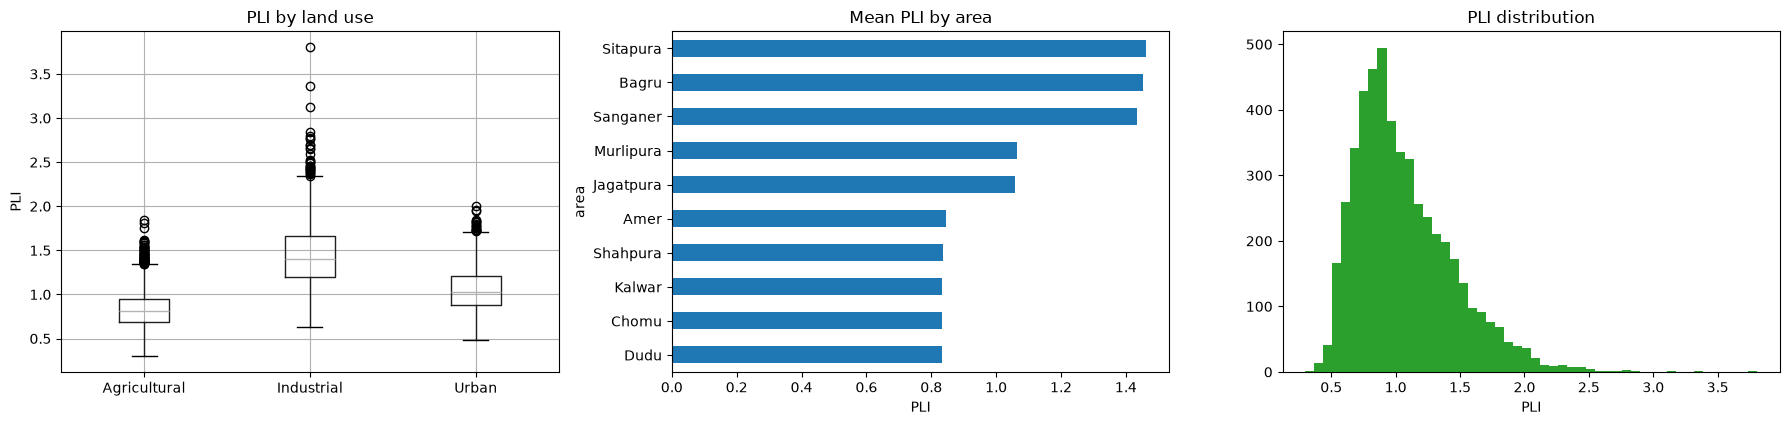

In [10]:
# ---- quick exploratory plots -------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
combined.boxplot(column=TARGET, by="land_use", ax=ax[0]); ax[0].set(title="PLI by land use", xlabel="", ylabel="PLI")
combined.groupby("area")[TARGET].mean().sort_values().plot.barh(ax=ax[1]); ax[1].set(title="Mean PLI by area", xlabel="PLI")
ax[2].hist(combined[TARGET], bins=50, color="tab:green"); ax[2].set(title="PLI distribution", xlabel="PLI")
plt.suptitle(""); plt.tight_layout()
plt.savefig(BASE_DIR / "reports/eda_plots.png", dpi=120); plt.show()

---
# Task 2 – ML Model Development  (24/08/2026 – 03/10/2026)



In [11]:
NUMERIC_FEATURES = ["latitude", "longitude", "soil_pH", "organic_carbon_pct", "gw_nearest_km"] + GW_FEATURES
CATEGORICAL_FEATURES = ["land_use"]
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
LAND_USES = sorted(combined["land_use"].unique().tolist())

def make_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric, NUMERIC_FEATURES), ("cat", categorical, CATEGORICAL_FEATURES)])

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

X, y = combined[MODEL_FEATURES], combined[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape, " Land uses:", LAND_USES)

baseline = {
    "LR":  LinearRegression(),
    "RF":  RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVR(kernel="rbf", C=1.0, epsilon=0.1),
    "ANN": MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
}

Train: (3999, 18)  Test: (1000, 18)  Land uses: ['Agricultural', 'Industrial', 'Urban']


In [12]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in baseline.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                         scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error",
                                  "mae": "neg_mean_absolute_error"})
    rows.append({"Model": name, "CV R2": res["test_r2"].mean(), "CV R2 std": res["test_r2"].std(),
                 "CV RMSE": -res["test_rmse"].mean(), "CV MAE": -res["test_mae"].mean()})
baseline_df = pd.DataFrame(rows).set_index("Model").round(4)
baseline_df.to_csv(BASE_DIR / "reports/baseline_results.csv")
print("Baseline models – 5-fold cross-validation on the training split (test split untouched)")
display(baseline_df)

Baseline models – 5-fold cross-validation on the training split (test split untouched)


,CV R2,CV R2 std,CV RMSE,CV MAE
Model,,,,
LR,0.4820,0.0314,0.2715,0.2052
RF,0.4367,0.0268,0.2832,0.2136
SVM,0.4664,0.0254,0.2756,0.2051
ANN,0.4657,0.0361,0.2757,0.2082


---
# Task 3 – Model Training & Evaluation  (14/09/2026 – 21/10/2026)



In [13]:
SEARCH = {
    "LR": (LinearRegression(), {"model__fit_intercept": [True, False]}),
    "RF": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
           {"model__n_estimators": [100, 150, 200], "model__max_depth": [6, 8, 12],
            "model__min_samples_leaf": [5, 10, 20], "model__max_features": [0.4, 0.6, 0.8]}),
    "SVM": (SVR(kernel="rbf"),
            {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03, 0.1],
             "model__epsilon": [0.05, 0.1, 0.2]}),
    "ANN": (MLPRegressor(early_stopping=True, max_iter=800, random_state=RANDOM_STATE),
            {"model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
             "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "model__learning_rate_init": [1e-3, 3e-3, 1e-2],
             "model__activation": ["relu", "tanh"]}),
}

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": mean_absolute_error(y_true, y_pred),
            "Polluted/not accuracy": float(((y_true > 1) == (y_pred > 1)).mean())}

tuned, rows = {}, []
for name, (est, space) in SEARCH.items():
    n_combo = int(np.prod([len(v) for v in space.values()]))
    search = RandomizedSearchCV(make_pipeline(est), space, n_iter=min(N_ITER, n_combo), cv=cv,
                                scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE,
                                n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    m = evaluate(y_test, search.predict(X_test))
    rows.append({"Model": name, "CV RMSE": -search.best_score_, **m,
                 "Best parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    print(f"{name:4s} done | CV RMSE={-search.best_score_:.4f} | test R2={m['R2']:.4f}")

results = pd.DataFrame(rows).set_index("Model")

# unseen-area check on the TRAINING split only (test split stays untouched)
groups_train = combined.loc[X_train.index, "area"]
for name, mdl in tuned.items():
    p = cross_val_predict(clone(mdl), X_train, y_train, cv=LeaveOneGroupOut(), groups=groups_train, n_jobs=1)
    results.loc[name, "Unseen-area RMSE"] = float(np.sqrt(mean_squared_error(y_train, p)))
    results.loc[name, "Unseen-area R2"] = r2_score(y_train, p)

best_name = results["Unseen-area RMSE"].idxmin()
best_model = tuned[best_name]
print("\nBest model (lowest unseen-area RMSE):", best_name)
display(results.drop(columns="Best parameters").round(4))
for n in results.index:
    print(n, "->", results.loc[n, "Best parameters"])
results.assign(**{"Best parameters": results["Best parameters"].astype(str)}).round(4).to_csv(
    BASE_DIR / "reports/model_comparison.csv")

LR   done | CV RMSE=0.2715 | test R2=0.4804
RF   done | CV RMSE=0.2739 | test R2=0.4817
SVM  done | CV RMSE=0.2741 | test R2=0.4636
ANN  done | CV RMSE=0.2755 | test R2=0.4695

Best model (lowest unseen-area RMSE): RF


,CV RMSE,R2,RMSE,MAE,Polluted/not accuracy,Unseen-area RMSE,Unseen-area R2
Model,,,,,,,
LR,0.2715,0.4804,0.2809,0.2090,0.788,0.5241,-0.9266
RF,0.2739,0.4817,0.2805,0.2084,0.789,0.2927,0.3991
SVM,0.2741,0.4636,0.2854,0.2086,0.788,0.3595,0.0934
ANN,0.2755,0.4695,0.2838,0.2108,0.789,0.4534,-0.4416


LR -> {'fit_intercept': True}
RF -> {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.4, 'max_depth': 6}
SVM -> {'gamma': 0.01, 'epsilon': 0.05, 'C': 10}
ANN -> {'learning_rate_init': 0.003, 'hidden_layer_sizes': (32,), 'alpha': 0.1, 'activation': 'relu'}


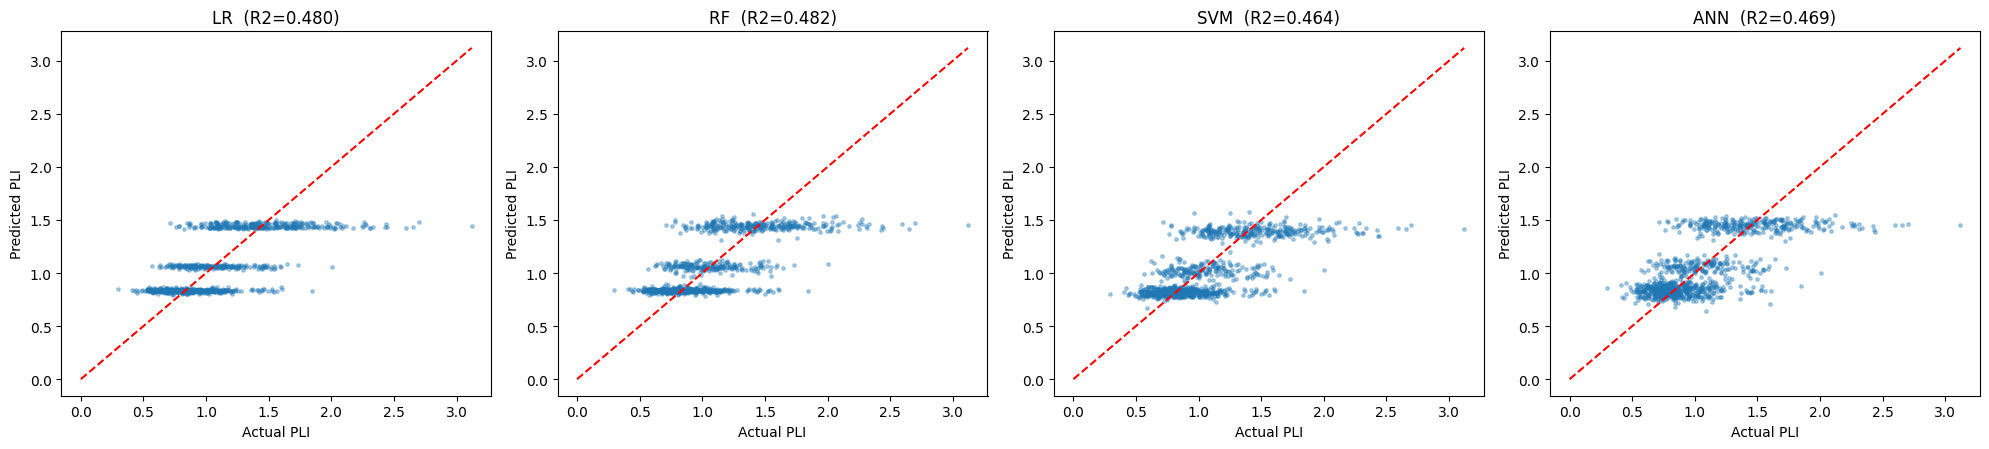

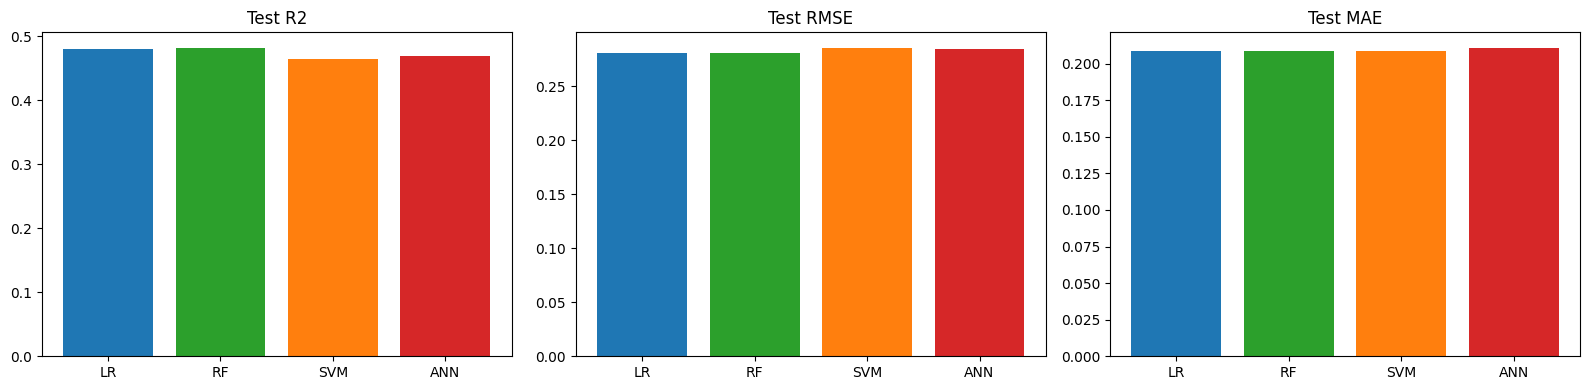

In [13]:
# ---- actual vs predicted for all four models + comparison bar -----------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
lim = [0, float(max(y_test.max(), 3))]
for ax, (name, mdl) in zip(axes, tuned.items()):
    pred = mdl.predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=0.35)
    ax.plot(lim, lim, "r--")
    ax.set(title=f"{name}  (R2={r2_score(y_test, pred):.3f})", xlabel="Actual PLI", ylabel="Predicted PLI")
plt.tight_layout(); plt.savefig(BASE_DIR / "reports/actual_vs_predicted.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, metric in enumerate(["R2", "RMSE", "MAE"]):
    ax[i].bar(results.index, results[metric], color=["tab:blue", "tab:green", "tab:orange", "tab:red"])
    ax[i].set(title=f"Test {metric}")
plt.tight_layout(); plt.savefig(BASE_DIR / "reports/model_comparison.png", dpi=120); plt.show()

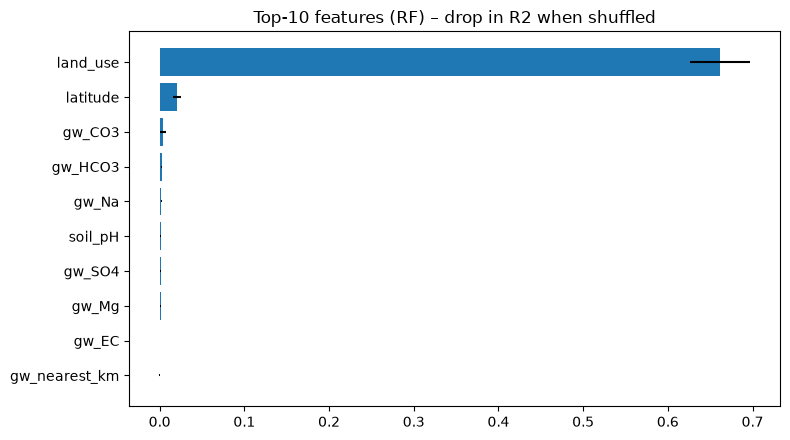

,feature,importance,std
17,land_use,0.6619,0.0356
0,latitude,0.0204,0.0043
7,gw_CO3,0.0043,0.0035
8,gw_HCO3,0.0024,0.0007
15,gw_Na,0.0021,0.0009
2,soil_pH,0.0015,0.0006
11,gw_SO4,0.0011,0.0009
14,gw_Mg,0.0011,0.0005


In [14]:
# ---- feature importance of the best model (permutation importance, test set) --------
imp = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                             scoring="r2", n_jobs=1)
imp_df = pd.DataFrame({"feature": MODEL_FEATURES, "importance": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("importance", ascending=False)
imp_df.to_csv(BASE_DIR / "reports/feature_importance.csv", index=False)
top = imp_df.head(10).iloc[::-1]
plt.figure(figsize=(8, 4.5)); plt.barh(top["feature"], top["importance"], xerr=top["std"])
plt.title(f"Top-10 features ({best_name}) – drop in R2 when shuffled"); plt.tight_layout()
plt.savefig(BASE_DIR / "reports/feature_importance.png", dpi=120); plt.show()
display(imp_df.head(8).round(4))

In [16]:
# ---- generalisation to UNSEEN areas (leave-one-area-out) + leakage diagnostic -------------
logo_pred = cross_val_predict(clone(best_model), X, y, cv=LeaveOneGroupOut(), groups=combined["area"])
area_metrics = evaluate(y, logo_pred)
print(f"Leave-one-area-out on ALL data ({best_name}):", {k: round(v, 4) for k, v in area_metrics.items()})

# Diagnostic only: using metal concentrations as inputs gives a near-perfect score because PLI is
# computed from them (data leakage) -> this is why they are NOT used as model inputs.
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(combined[METAL_COLUMNS], y, test_size=0.2, random_state=RANDOM_STATE)
leak_r2 = r2_score(ym_te, RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
                   .fit(Xm_tr, ym_tr).predict(Xm_te))
print(f"Diagnostic (RF on metal concentrations, leakage): R2 = {leak_r2:.3f}")

Leave-one-area-out on ALL data (RF): {'R2': 0.4181, 'RMSE': 0.2899, 'MAE': 0.2199, 'Polluted/not accuracy': 0.7271}
Diagnostic (RF on metal concentrations, leakage): R2 = 0.983


In [17]:
# ---- save best model + metadata ----------------------------------------------------------------
joblib.dump(best_model, BASE_DIR / "models/best_model.joblib")
meta = {
    "model_name": best_name, "target": TARGET, "features": MODEL_FEATURES,
    "land_use_categories": LAND_USES,
    "best_params": {k: str(v) for k, v in results.loc[best_name, "Best parameters"].items()},
    "test_metrics": {k: float(v) for k, v in results.loc[best_name, ["R2", "RMSE", "MAE", "Polluted/not accuracy"]].items()},
    "leave_one_area_out_metrics": {k: float(v) for k, v in area_metrics.items()},
    "all_models_test_r2": {n: float(results.loc[n, "R2"]) for n in results.index},
    "sklearn_version": sklearn.__version__, "python_version": platform.python_version(),
    "note": ("Soil data is SIMULATED (4,999 rows). Groundwater chemistry is joined by location; "
             "the CGWB file has no heavy-metal data. Treat metrics as a pipeline demonstration."),
}
with open(BASE_DIR / "models/model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)
print("Saved models/best_model.joblib and models/model_meta.json")
print(json.dumps(meta["test_metrics"], indent=2))

Saved models/best_model.joblib and models/model_meta.json
{
  "R2": 0.48174968544318875,
  "RMSE": 0.2805342933586146,
  "MAE": 0.20836763299775887,
  "Polluted/not accuracy": 0.789
}


---
# Task 4 – ML–Backend Integration  (13/10/2026 – 02/01/2027)



In [18]:
%%writefile backend_app.py
"""Flask API that serves the trained PLI model.   Run:  python backend_app.py"""
import json
import math
from pathlib import Path

import joblib
import pandas as pd
from flask import Flask, jsonify, request

from gw_utils import GW_FEATURES, GW_MAX_DISTANCE_KM, gw_features_for_points, risk_class

BASE_DIR = Path(__file__).resolve().parent
MODEL_FILE = BASE_DIR / "models" / "best_model.joblib"
META_FILE = BASE_DIR / "models" / "model_meta.json"
STATION_FILE = BASE_DIR / "data" / "processed" / "gw_station_table.csv"

app = Flask(__name__)
_state = {"model": None, "meta": None, "stations": None}

REQUIRED = ["latitude", "longitude", "land_use", "soil_pH", "organic_carbon_pct"]
LIMITS = {"latitude": (20.0, 32.0), "longitude": (68.0, 80.0),
          "soil_pH": (3.0, 11.0), "organic_carbon_pct": (0.0, 20.0)}
MAX_BATCH = 1000


class ValidationError(ValueError):
    pass


def load_artifacts():
    if _state["model"] is None:
        if not MODEL_FILE.exists() or not META_FILE.exists() or not STATION_FILE.exists():
            raise FileNotFoundError("Model files not found. Run the notebook (Task 1-3) first.")
        _state["model"] = joblib.load(MODEL_FILE)
        with open(META_FILE, encoding="utf-8") as f:
            _state["meta"] = json.load(f)
        _state["stations"] = pd.read_csv(STATION_FILE)


def _to_float(payload, key):
    try:
        val = float(payload[key])
    except (TypeError, ValueError):
        raise ValidationError(f"'{key}' must be a number")
    if math.isnan(val) or math.isinf(val):
        raise ValidationError(f"'{key}' must be a finite number")
    return val


def build_feature_frame(samples):
    land_uses = _state["meta"]["land_use_categories"]
    rows = []
    for i, s in enumerate(samples):
        if not isinstance(s, dict):
            raise ValidationError(f"sample {i}: must be a JSON object")
        missing = [k for k in REQUIRED if k not in s]
        if missing:
            raise ValidationError(f"sample {i}: missing field(s) {missing}")
        row = {}
        try:
            for k in ("latitude", "longitude", "soil_pH", "organic_carbon_pct"):
                row[k] = _to_float(s, k)
                lo, hi = LIMITS[k]
                if not lo <= row[k] <= hi:
                    raise ValidationError(f"'{k}' must be between {lo} and {hi}")
            lu = str(s["land_use"]).strip().title()
            if lu not in land_uses:
                raise ValidationError(f"'land_use' must be one of {land_uses}")
            row["land_use"] = lu
            for g in GW_FEATURES:  # optional manual groundwater override
                row["_user_" + g] = _to_float(s, g) if s.get(g) is not None else None
        except ValidationError as e:
            raise ValidationError(f"sample {i}: {e}")
        rows.append(row)

    df = pd.DataFrame(rows)
    gw = gw_features_for_points(df["latitude"], df["longitude"], _state["stations"])
    for g in GW_FEATURES:
        user = df["_user_" + g].astype(float)
        df[g] = user.where(user.notna(), gw[g])
    df["gw_nearest_km"] = gw["gw_nearest_km"]
    df["_gw_stations_used"] = gw["gw_stations_used"]
    return df


def predict_samples(samples):
    load_artifacts()
    df = build_feature_frame(samples)
    preds = _state["model"].predict(df[_state["meta"]["features"]])
    out = []
    for i, p in enumerate(preds):
        p = max(0.0, float(p))  # PLI cannot be negative
        warnings = []
        if df.loc[i, "_gw_stations_used"] == 0:
            warnings.append(f"No groundwater station within {GW_MAX_DISTANCE_KM:.0f} km; "
                            "groundwater features were imputed with training medians.")
        near = df.loc[i, "gw_nearest_km"]
        out.append({"predicted_PLI": round(p, 4), "risk_class": risk_class(p), "polluted": bool(p > 1),
                    "nearest_groundwater_station_km": None if pd.isna(near) else round(float(near), 2),
                    "warnings": warnings})
    return out


@app.after_request
def add_cors(resp):
    resp.headers["Access-Control-Allow-Origin"] = "*"
    resp.headers["Access-Control-Allow-Headers"] = "Content-Type"
    resp.headers["Access-Control-Allow-Methods"] = "GET, POST, OPTIONS"
    return resp


@app.errorhandler(ValidationError)
def handle_validation(e):
    return jsonify(error=str(e)), 400


@app.errorhandler(404)
def handle_404(e):
    return jsonify(error="not found"), 404


@app.errorhandler(405)
def handle_405(e):
    return jsonify(error="method not allowed"), 405


@app.errorhandler(Exception)
def handle_unexpected(e):
    app.logger.exception("unexpected error")
    return jsonify(error="internal server error", detail=str(e)), 500


@app.get("/")
def index():
    return jsonify(service="Soil + Groundwater heavy-metal index (PLI) prediction API",
                   endpoints=["/health", "/model-info", "/predict", "/predict/batch"])


@app.get("/health")
def health():
    try:
        load_artifacts()
        return jsonify(status="ok", model_loaded=True)
    except FileNotFoundError as e:
        return jsonify(status="error", model_loaded=False, detail=str(e)), 503


@app.get("/model-info")
def model_info():
    load_artifacts()
    m = _state["meta"]
    return jsonify(model_name=m["model_name"], target=m["target"], required_fields=REQUIRED,
                   optional_fields=GW_FEATURES, land_use_values=m["land_use_categories"],
                   test_metrics=m["test_metrics"], all_models_test_r2=m["all_models_test_r2"],
                   leave_one_area_out_metrics=m["leave_one_area_out_metrics"], note=m["note"])


@app.post("/predict")
def predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        raise ValidationError("body must be a JSON object")
    return jsonify(predict_samples([payload])[0])


@app.post("/predict/batch")
def predict_batch():
    payload = request.get_json(silent=True)
    samples = payload.get("samples") if isinstance(payload, dict) else payload
    if not isinstance(samples, list) or not samples:
        raise ValidationError('body must be a non-empty JSON list or {"samples": [...]}')
    if len(samples) > MAX_BATCH:
        raise ValidationError(f"maximum batch size is {MAX_BATCH}")
    results = predict_samples(samples)
    return jsonify(count=len(results), predictions=results)


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)

Overwriting backend_app.py


In [19]:
# ---- automatic API tests (Flask test client – no server needed) -------------------------------
import backend_app
importlib.reload(backend_app)
client = backend_app.app.test_client()
failures = []

def check(name, cond, extra=""):
    print(f"[{'PASS' if cond else 'FAIL'}] {name} {extra}")
    if not cond:
        failures.append(name)

GOOD = {"latitude": 26.80, "longitude": 75.80, "land_use": "Industrial", "soil_pH": 7.9, "organic_carbon_pct": 0.7}

r = client.get("/health");      check("GET /health", r.status_code == 200 and r.json["model_loaded"])
r = client.get("/model-info");  check("GET /model-info", r.status_code == 200 and "test_metrics" in r.json)
r = client.post("/predict", json=GOOD)
check("POST /predict", r.status_code == 200 and "predicted_PLI" in r.json, str(r.json))
ind = r.json["predicted_PLI"]
r = client.post("/predict", json={**GOOD, "land_use": "agricultural"}); agri = r.json["predicted_PLI"]
check("industrial PLI > agricultural PLI", ind > agri, f"({ind} vs {agri})")
r = client.post("/predict", json={**GOOD, "gw_pH": 7.5, "gw_EC": 1800}); check("manual groundwater override", r.status_code == 200)
r = client.post("/predict", json={k: v for k, v in GOOD.items() if k != "soil_pH"}); check("missing field -> 400", r.status_code == 400)
r = client.post("/predict", json={**GOOD, "land_use": "Forest"});  check("bad land_use -> 400", r.status_code == 400)
r = client.post("/predict", json={**GOOD, "soil_pH": "abc"});      check("non-numeric -> 400", r.status_code == 400)
r = client.post("/predict", json={**GOOD, "latitude": 0});         check("latitude out of range -> 400", r.status_code == 400)
r = client.post("/predict", data="not json", content_type="text/plain"); check("non-JSON body -> 400", r.status_code == 400)
r = client.post("/predict", json={**GOOD, "latitude": 21.0, "longitude": 79.5})
check("no station nearby -> warning, still 200", r.status_code == 200 and len(r.json["warnings"]) == 1)
r = client.post("/predict/batch", json={"samples": [GOOD, {**GOOD, "land_use": "Urban"}]})
check("POST /predict/batch", r.status_code == 200 and r.json["count"] == 2)
r = client.post("/predict/batch", json=[]);  check("empty batch -> 400", r.status_code == 400)
r = client.get("/nope");                     check("unknown route -> 404", r.status_code == 404)

assert not failures, f"Failed tests: {failures}"
print("\nALL API TESTS PASSED")

[PASS] GET /health 
[PASS] GET /model-info 
[PASS] POST /predict {'nearest_groundwater_station_km': 4.76, 'polluted': True, 'predicted_PLI': 1.4533, 'risk_class': 'Moderate (1 < PLI <= 2)', 'warnings': []}
[PASS] industrial PLI > agricultural PLI (1.4533 vs 0.9227)
[PASS] manual groundwater override 
[PASS] missing field -> 400 
[PASS] bad land_use -> 400 
[PASS] non-numeric -> 400 
[PASS] latitude out of range -> 400 
[PASS] non-JSON body -> 400 
[PASS] no station nearby -> warning, still 200 
[PASS] POST /predict/batch 
[PASS] empty batch -> 400 
[PASS] unknown route -> 404 

ALL API TESTS PASSED


In [21]:
# ---- final summary --------------------------------------------------------------------------------------
print("=" * 70)
print("PROJECT SUMMARY")
print("=" * 70)
print(f"Combined dataset : {combined.shape[0]} rows x {combined.shape[1]} columns")
print(f"Best model       : {best_name}")
print("Test metrics     :", {k: round(v, 4) for k, v in meta['test_metrics'].items()})
print("Unseen-area R2   :", round(area_metrics['R2'], 4))
print("\nAll models (test R2):")
print(results[["CV RMSE", "Unseen-area RMSE", "Unseen-area R2", "R2", "RMSE", "MAE"]].round(4).to_string())


PROJECT SUMMARY
Combined dataset : 4999 rows x 33 columns
Best model       : RF
Test metrics     : {'R2': 0.4817, 'RMSE': 0.2805, 'MAE': 0.2084, 'Polluted/not accuracy': 0.789}
Unseen-area R2   : 0.4181

All models (test R2):
       CV RMSE  Unseen-area RMSE  Unseen-area R2      R2    RMSE     MAE
Model                                                                   
LR      0.2715            0.5241         -0.9266  0.4804  0.2809  0.2090
RF      0.2739            0.2927          0.3991  0.4817  0.2805  0.2084
SVM     0.2741            0.3595          0.0934  0.4636  0.2854  0.2086
ANN     0.2755            0.4534         -0.4416  0.4695  0.2838  0.2108
